# Parkinson’s Disease Detection Using Machine Learning
**Machine Learning and Algorithms | M.Tech CSIS**  
 Sneha Theertha A D

## Project overview
This notebook demonstrates a complete supervised machine-learning workflow using biomedical voice measurements from the UCI Parkinson’s Disease dataset. It compares **Support Vector Machine (SVM), K-Nearest Neighbours (KNN), Decision Tree, and Random Forest**.



## 1. Setup


In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy matplotlib scikit-learn ipywidgets

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    roc_auc_score
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
print("Setup complete.")

Setup complete.


## 2. Load the dataset
The notebook downloads the public `parkinsons.data` file from the UCI Machine Learning Repository. Internet access is needed for this step.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data"

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset loaded successfully.")
except Exception as e:
    raise RuntimeError(
        "Could not download the UCI dataset. Check your internet connection, "
        "then rerun this cell. You can also download parkinsons.data from the "
        "UCI Parkinson's Disease dataset page and load it with "
        "pd.read_csv('parkinsons.data')."
    ) from e

display(df.head())
print("Dataset shape:", df.shape)

Dataset loaded successfully.


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


Dataset shape: (195, 24)


## 3. Explore and prepare the data
`status` is the target column in the original dataset: **1 = Parkinson’s group in this dataset; 0 = control group**. These labels describe the dataset, not a reliable diagnosis for a new person.

In [3]:
print("Column names:")
print(df.columns.tolist())
print("\\nMissing values:", int(df.isnull().sum().sum()))
print("\\nTarget counts:")
display(df["status"].value_counts().rename(index={0: "Control (0)", 1: "Parkinson's group (1)"}))

# The participant/file identifier is not a predictive measurement, so remove it.
X = df.drop(columns=["name", "status"])
y = df["status"].astype(int)

feature_names = X.columns.tolist()
print(f"Number of input features: {len(feature_names)}")
print("Input features:", feature_names)

Column names:
['name', 'MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP', 'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA', 'NHR', 'HNR', 'status', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']
\nMissing values: 0
\nTarget counts:


,count
status,
Parkinson's group (1),147
Control (0),48


Number of input features: 22
Input features: ['MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP', 'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']


## 4. Split data and define the models
We use a stratified train/test split so both sets retain a similar class balance. Scaling is included in the SVM and KNN pipelines because these methods are sensitive to feature scales.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

models = {
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
        ))
    ])
}

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Models ready:", ", ".join(models.keys()))

Training rows: 146
Testing rows: 49
Models ready: SVM, KNN, Decision Tree, Random Forest


## 5. Train and compare the algorithms
Metrics are calculated on the held-out test set. The values can vary if you change the split or model settings.

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.918,0.923,0.973,0.947
1,KNN,0.898,0.900,0.973,0.935
2,SVM,0.878,0.860,1.000,0.925
3,Decision Tree,0.837,0.914,0.865,0.889


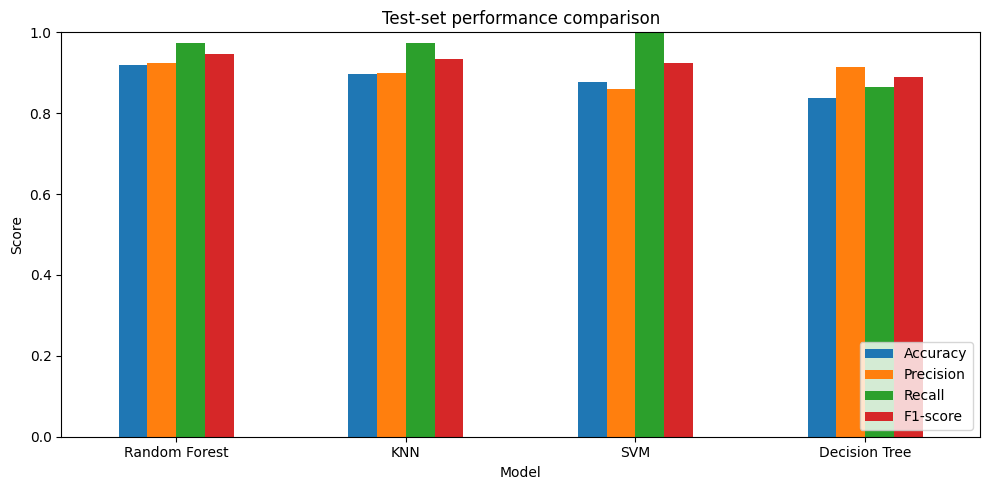

In [5]:
trained_models = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}", "F1-score": "{:.3f}"
}))

ax = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)
ax.set_title("Test-set performance comparison")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 6. Confusion matrix and classification report
A confusion matrix summarizes correct and incorrect class predictions. Recall is especially worth inspecting because it shows how many positive examples were identified in this test split.

Top model by test F1-score: Random Forest
\nClassification report:
                       precision    recall  f1-score   support

          Control (0)       0.90      0.75      0.82        12
Parkinson's group (1)       0.92      0.97      0.95        37

             accuracy                           0.92        49
            macro avg       0.91      0.86      0.88        49
         weighted avg       0.92      0.92      0.92        49



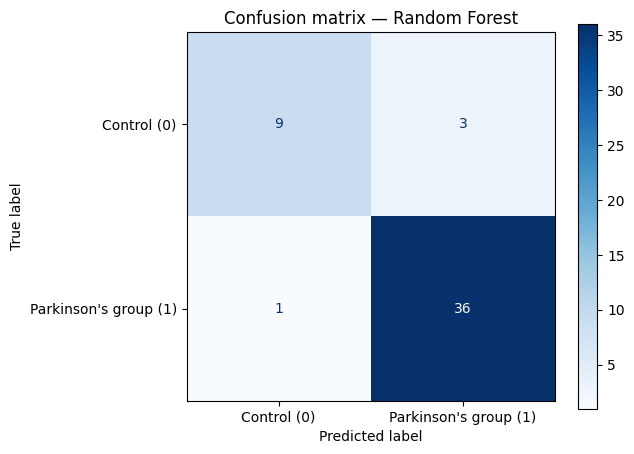

In [6]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print("Top model by test F1-score:", best_model_name)
print("\\nClassification report:")
print(classification_report(
    y_test, best_model.predict(X_test),
    target_names=["Control (0)", "Parkinson's group (1)"],
    zero_division=0
))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test,
    display_labels=["Control (0)", "Parkinson's group (1)"],
    cmap="Blues"
)
plt.title(f"Confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 7. ROC curves
ROC curves compare the true-positive and false-positive rates across thresholds. AUC is a summary measure; it does not establish clinical usefulness.

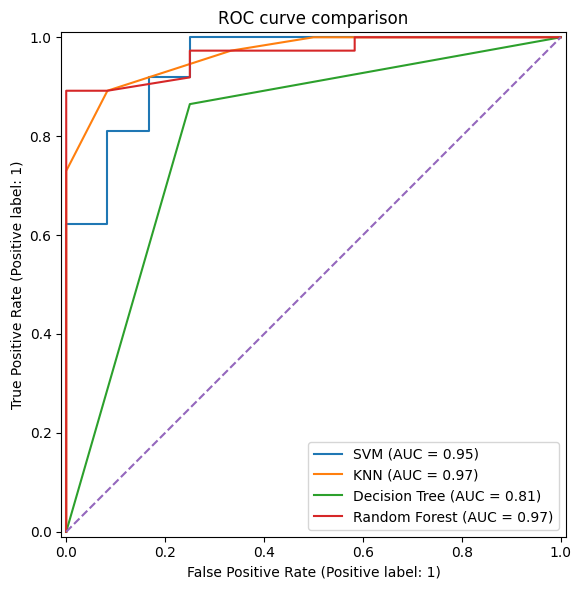

SVM ROC-AUC: 0.946
KNN ROC-AUC: 0.965
Decision Tree ROC-AUC: 0.807
Random Forest ROC-AUC: 0.966


In [7]:
plt.figure(figsize=(8, 6))
for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.title("ROC curve comparison")
plt.tight_layout()
plt.show()

for name, model in trained_models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    print(f"{name} ROC-AUC: {roc_auc_score(y_test, probabilities):.3f}")

## 8. Feature importance (Random Forest)
This gives a rough view of which input features the fitted Random Forest used most. Importance is not proof of cause or medical significance.

,Importance
PPE,0.132118
spread1,0.099144
MDVP:APQ,0.066101
Shimmer:APQ5,0.062708
spread2,0.049790
MDVP:Fhi(Hz),0.048890
NHR,0.046653
MDVP:Fo(Hz),0.044968
Shimmer:DDA,0.044203
Shimmer:APQ3,0.042939


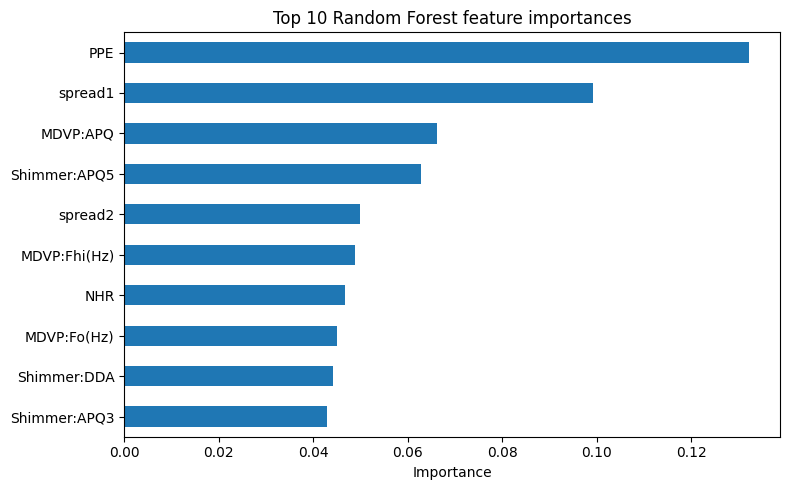

In [8]:
rf = trained_models["Random Forest"].named_steps["model"]
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)
display(importance.head(10).rename("Importance").to_frame())

importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Random Forest feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 9. Interactive input demo
Run this cell to create an input form. It starts with a real example row from the dataset so the demo works immediately. You can change the numerical values, select a model, and click **Predict sample**.

The features are biomedical voice measurements; values should be entered in the dataset's original units. Avoid interpreting the output as a personal medical result.

In [9]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Start with a row from the test set, for a convenient demonstration.
demo_values = X_test.iloc[0].to_dict()

feature_widgets = {}
for feature in feature_names:
    value = float(demo_values[feature])
    # A text field allows entry of any numeric value and preserves small decimal values.
    feature_widgets[feature] = widgets.FloatText(
        value=value,
        description=feature,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="430px")
    )

model_dropdown = widgets.Dropdown(
    options=list(trained_models.keys()),
    value=best_model_name,
    description="Model:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="300px")
)
predict_button = widgets.Button(description="Predict sample", button_style="primary")
reset_button = widgets.Button(description="Reset to example", button_style="")
output = widgets.Output()

left_features = feature_names[:len(feature_names)//2]
right_features = feature_names[len(feature_names)//2:]
feature_form = widgets.HBox([
    widgets.VBox([feature_widgets[f] for f in left_features]),
    widgets.VBox([feature_widgets[f] for f in right_features])
])

def reset_demo(_):
    for f in feature_names:
        feature_widgets[f].value = float(demo_values[f])
    output.clear_output()

def run_prediction(_):
    with output:
        clear_output()
        try:
            row = pd.DataFrame(
                [[float(feature_widgets[f].value) for f in feature_names]],
                columns=feature_names
            )
            chosen_name = model_dropdown.value
            chosen_model = trained_models[chosen_name]
            prediction = int(chosen_model.predict(row)[0])
            probability = float(chosen_model.predict_proba(row)[0, 1])

            label = (
                "Class 1 — resembles the Parkinson's group in this dataset"
                if prediction == 1
                else "Class 0 — resembles the control group in this dataset"
            )
            print("Selected model:", chosen_name)
            print("Model output:", label)
            print(f"Estimated class-1 probability: {probability:.1%}")
            print("\\nEducational demonstration only. This is NOT a medical diagnosis.")
        except Exception as exc:
            print("Could not make prediction:", exc)

predict_button.on_click(run_prediction)
reset_button.on_click(reset_demo)

display(Markdown("**Enter or edit the feature values below:**"))
display(model_dropdown)
display(feature_form)
display(widgets.HBox([predict_button, reset_button]))
display(output)

**Enter or edit the feature values below:**

Dropdown(description='Model:', index=3, layout=Layout(width='300px'), options=('SVM', 'KNN', 'Decision Tree', …

Output()

In [10]:
# Manual-input alternative (works without interactive widgets)
# The example below uses the first test row. Replace values as needed.
manual_input = X_test.iloc[[0]].copy()

# Example: change one value by editing the next line, then run this cell.
# manual_input.loc[manual_input.index[0], "MDVP:Fo(Hz)"] = 150.0

manual_model_name = best_model_name
manual_model = trained_models[manual_model_name]
manual_prediction = int(manual_model.predict(manual_input)[0])
manual_probability = float(manual_model.predict_proba(manual_input)[0, 1])

print("Model:", manual_model_name)
print("Predicted dataset class:", manual_prediction)
print(f"Estimated class-1 probability: {manual_probability:.1%}")
print("Academic demonstration only — not a medical diagnosis.")

Model: Random Forest
Predicted dataset class: 1
Estimated class-1 probability: 93.0%
Academic demonstration only — not a medical diagnosis.


## 10. Conclusion
- The project loads and explores the UCI voice-measurement dataset.
- It preprocesses the features and compares SVM, KNN, Decision Tree, and Random Forest.
- It evaluates performance using accuracy, precision, recall, F1-score, confusion matrices, and ROC curves.
- It includes a user-input prediction demo.

**Limitations:** The dataset is relatively small and model performance on this split may not generalize to new populations or recording conditions. The model is for learning and demonstration only, not clinical use.